# vibrational.gap.ir_raman

下面的单元格读取真实冻结模型运行结果，重新核算并绘图；它们不等于再次运行模型。来源文件和哈希可追溯到原始推理，不使用假想预测。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('vibrational.gap.ir_raman')
print(json.dumps({'task': evidence['task'], 'status': evidence['status'], 'source_sha256': evidence['source_hashes']}, indent=2, ensure_ascii=False))

{
  "task": "vibrational.gap.ir_raman",
  "status": "recorded_results",
  "source_sha256": {
    "gap_protocol_random128_20261116.json": "e3ab614192106dccc2bb4cf30d4a2ce0259ba6e21207bb52695a0a02ef08d488"
  }
}


## 实际输入与输出

使用记录中的第一例。超过八项的数组会显示长度和缩略值，完整数值保存在可下载证据 JSON 中。

In [2]:
example = evidence['examples'][0]
print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "sample_id": "ZINCV2-ZINC000666646493",
  "output": {
    "gap_ev": 6.397045948032148
  },
  "reference": {
    "gap_ev": 5.227035183991835
  },
  "input": {
    "ir": {
      "length": 1024,
      "first_values": [
        0.010713187977671623,
        0.013313207775354385,
        0.017257077619433403,
        0.021930798888206482,
        0.02480231784284115,
        0.023212244734168053,
        0.018831992521882057,
        0.014817541465163231
      ]
    },
    "raman": {
      "length": 1024,
      "first_values": [
        0.007774287834763527,
        0.010057443752884865,
        0.0145131079480052,
        0.01943223364651203,
        0.020987847819924355,
        0.017073912546038628,
        0.012731233611702919,
        0.01178628858178854
      ]
    }
  }
}


## 实际运行指标与重新核算

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded sample | recorded model | mae_ev | 1.27764 |
| recorded sample | recorded model | rmse_ev | 1.4789 |
| recorded sample | recorded model | examples | 128 |
| recorded sample | Training-mean baseline | mae_ev | 0.89994 |
| recorded sample | Training-mean baseline | rmse_ev | 1.06962 |
| recorded sample | Training-mean baseline | examples | 128 |


{
  "paired_values": 128,
  "mae": 1.2776368534375264,
  "rmse": 1.4789026993553864,
  "unit": "eV"
}


## 预测／参考对照图

这是四模态权重的缺通道消融。不能当作独立 IR/Raman 专用模型；需相容权重或另行规划适配。

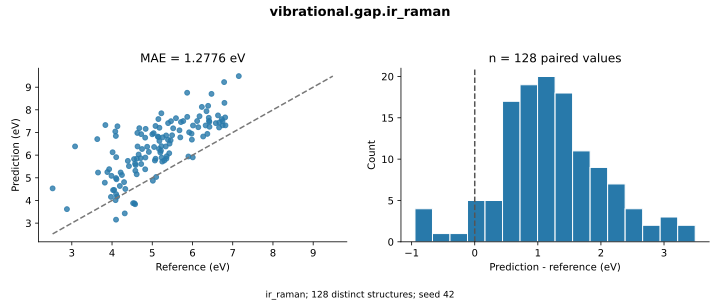

In [4]:
figure = render('vibrational.gap.ir_raman', evidence)
image = io.StringIO()
figure.savefig(image, format='svg', metadata={'Date': None})
display(SVG(image.getvalue()))
import matplotlib.pyplot as plt
plt.close(figure)

## 重新执行模型

按任务页面与 Quick Start 配置原模型运行环境、checkpoint 和数据。上面的分析单元格只需要文档示例环境。

[Task](../tasks/vibrational-gap-ir_raman.md) · [Quick Start](../quickstart.md)
